# Deciphering the Decision Logic of an AI Microscopy Agent

### Completed CAMM Hackathon — data-backed, reproducible, and trace-aware

**Research question.** Can we infer the visual and spatial preferences behind GPT's sequence of AFM measurement choices? Each decision chooses one patch from 20 candidate images. Here we reconstruct candidate locations, test interpretable rewards, learn adaptive prediction models and audit generalization.

**Evaluation summary.** The principal prospective protocol uses **30 training + 30 validation + 40 untouched test choices per GPT trace**. Train/validation/test are split chronologically, with model selection made before evaluating each test suffix. Cross-trace generalization is reported separately. Eight simulated traces serve as diagnostic synthetic-policy tasks and are **not treated as GPT training labels**.

**Provenance.** Adapted from the uploaded `llm_decision_making(2).ipynb`; primary data are the 12 files linked in its official public [Drive folder](https://drive.google.com/drive/folders/1Gy7PeI4EhmlNE5hLxvP9p9A4u026QQ_X?usp=sharing). No API key or LLM call is necessary. This package contains the supplied data for offline reproducibility.

> Interpretability caveat: predictive correlations do not prove the private prompts, motivations, or literal thought process of GPT. All AFM patches originate from one source scan; independent-image generalization remains untested.

## 1. Setup and reproducibility

Run in the extracted submission directory, with `data/` adjacent to this notebook. The submitted package contains all original trace files and AFM image. Only common Python numerical libraries are needed; `igor2` and `gdown` are intentionally not required.

In [1]:
from pathlib import Path
import sys, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.ensemble import ExtraTreesClassifier

np.random.seed(42)
DATA_ROOT = next((p for p in [Path.cwd()/'data', Path.cwd(), Path('/content/day_20_data'), Path('/mnt/data')] if (p/'gpt_decision_trace_0.pkl').exists() or (p/'gpt_decision_trace_0.pkl.bin').exists()), None)
if DATA_ROOT is None:
    raise FileNotFoundError('AFM data missing. Extract the complete submission ZIP and open this notebook in the same directory as data/.')
OUTPUT_ROOT = Path.cwd()/'results'
FIG_DIR=Path.cwd()/'figures'
OUTPUT_ROOT.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':115, 'savefig.dpi':160, 'font.size':10, 'axes.titlesize':12,
   'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False})
COLORS={'gpt_decision_trace_0':'#2364AA', 'gpt_decision_trace_1':'#1D8A75', 'gpt_decision_trace_2':'#D98428'}
print('Data directory:',DATA_ROOT.resolve())
print('Reproducibility seed: 42')

Data directory: /mnt/data/AFM_Decision_Logic_Submission/data
Reproducibility seed: 42


### Auditable analysis implementation

The following code is embedded in the notebook so the `.ipynb` can execute without importing a separate custom Python module. An identical, easier-to-edit `hackathon_core.py` accompanies the submission.

In [2]:
"""Reproducible AFM agent choice model for CAMM decision-logic hackathon.
No API calls. Uses public supplied trace labels, optional raw IBW for spatial context.
"""
from pathlib import Path
import pickle
import hashlib
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter, laplace, sobel
from scipy.special import logsumexp, softmax
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesClassifier

SEED=42
ROOT=Path.cwd()
N_CANDIDATES=20


def load_data(folder=ROOT):
    folder=Path(folder)
    tr={}
    for prefix,count in [('gpt',3),('simulated',8)]:
        for j in range(count):
            name=f'{prefix}_decision_trace_{j}'
            hits=[folder/(name+'.pkl'),folder/(name+'.pkl.bin')]
            fp=next((x for x in hits if x.exists()),None)
            if fp is None:raise FileNotFoundError('Missing '+name+'; extract hackathon_data.zip or use linked public folder')
            # These are organizer-supplied trusted pickles; never unpickle untrusted files.
            with fp.open('rb') as f:trace=pickle.load(f)
            keys=sorted(trace)
            if keys!=list(range(100)):raise AssertionError((name,'unexpected steps',keys))
            arr=np.stack([np.asarray(trace[k]['patches'],dtype=np.float32) for k in keys])
            y=np.array([int(trace[k]['selected_candidate']) for k in keys],int)
            p=np.array([trace[k]['position'] for k in keys],int)
            assert arr.shape==(100,20,20,20) and np.all((y>=0)&(y<20))
            assert all(np.array_equal(arr[k,y[k]],np.asarray(trace[k]['selected_patch'])) for k in keys)
            tr[name]={'patches':arr,'choice':y,'position':p,'raw':trace}
    return tr


def read_ibw_amplitude(folder=ROOT):
    """Read v5 little-endian FLOAT32 organizer file without optional igor2 install.
    Assumes 256x256x6, explicitly validated against selected patches and positions.
    General IBW files may require an IBW parser such as igor2.
    """
    folder=Path(folder)
    filename=next((p for p in [folder/'scan_main_0000.ibw',folder/'scan_main_0000.ibw.bin'] if p.exists()),None)
    if filename is None: return None
    b=filename.read_bytes()
    if int.from_bytes(b[:2],'little')!=5:raise ValueError('Expected IBW version 5')
    n=256*256*6
    arr=np.frombuffer(b,dtype='<f4',count=n,offset=384).reshape((256,256,6),order='F')
    x=arr[:,:,2].T.copy()
    return ((x-x.min())/(x.max()-x.min())).astype(np.float32)


def feature_matrix(patches):
    """Feature rows = candidates. Image-only interpretable morphology/texture descriptors."""
    a=np.asarray(patches,dtype=np.float32).reshape((-1,20,20))
    n=a.shape[0]
    f={}
    def add(k,v):f[k]=np.asarray(v,dtype=np.float64).reshape(n)
    flat=a.reshape(n,-1)
    add('mean',flat.mean(1));add('std',flat.std(1));add('min',flat.min(1));add('max',flat.max(1))
    for q in [10,25,50,75,90]:add('q'+str(q),np.percentile(flat,q,axis=1))
    add('range_90_10',f['q90']-f['q10']);add('bright_fraction',np.mean(a>.60,axis=(1,2)))
    add('dark_fraction',np.mean(a<.15,axis=(1,2)))
    add('mean_abs_grad_x',np.mean(np.abs(np.diff(a,axis=2)),axis=(1,2)))
    add('mean_abs_grad_y',np.mean(np.abs(np.diff(a,axis=1)),axis=(1,2)))
    add('edge_energy',f['mean_abs_grad_x']+f['mean_abs_grad_y'])
    add('gradient_anisotropy',np.abs(f['mean_abs_grad_x']-f['mean_abs_grad_y']))
    add('max_grad',np.max(np.abs(np.diff(a,axis=2)),axis=(1,2)))
    add('laplacian_energy',np.abs(laplace(a,axes=(1,2))).mean((1,2)))
    add('local_variation',gaussian_filter((a-gaussian_filter(a,sigma=(0,1,1)))**2,sigma=(0,1,1)).mean((1,2)))
    add('blur_variance',gaussian_filter(a,sigma=(0,2,2)).var((1,2)))
    add('fine_texture',np.mean(np.abs(a-gaussian_filter(a,sigma=(0,2,2))),axis=(1,2)))
    add('center_mean',a[:,5:15,5:15].mean((1,2)))
    add('border_mean',(a.sum((1,2))-a[:,5:15,5:15].sum((1,2)))/300)
    add('center_contrast',f['center_mean']-f['border_mean'])
    add('row_difference',np.abs(a[:,:10].mean((1,2))-a[:,10:].mean((1,2))))
    add('col_difference',np.abs(a[:,:,:10].mean((1,2))-a[:,:,10:].mean((1,2))))
    # Entropy of global-scaled intensity counts; avoids histogram range inconsistency.
    bins=np.clip((flat*12).astype(int),0,11)
    counts=np.zeros((n,12),float)
    for k in range(12): counts[:,k]=(bins==k).sum(1)
    prob=counts/flat.shape[1]
    add('hist_entropy',-(prob*np.log(prob+1e-12)).sum(1))
    add('pixel_skew',(((flat-flat.mean(1,keepdims=True))/(flat.std(1,keepdims=True)+1e-7))**3).mean(1))
    add('high_spots',((a>f['q90'][:,None,None]).sum((1,2)))/400)
    add('spatial_entropy_proxy',np.mean(np.abs(np.diff(a,axis=1)),axis=(1,2))+np.mean(np.abs(np.diff(a,axis=2)),axis=(1,2)))
    return pd.DataFrame(f).replace([np.inf,-np.inf],0).fillna(0)


def candidate_centers(img, patches, strict=True):
    """Match 20x20 candidate windows to known AFM image exactly; outputs xy pixel centers.
    Assumes candidate patches are raw globally-normalized crops, not resized.
    """
    a=np.asarray(patches,dtype=np.float32).reshape(-1,20,20)
    # If same value appears more than once, disambiguate by full patch comparison.
    lookup={}
    pix=img[:237,:237]
    for y,x in zip(*np.indices(pix.shape).reshape(2,-1)):
        key=int(pix[y,x].view(np.int32))
        lookup.setdefault(key,[]).append((int(y),int(x)))
    ans=np.full((len(a),2),np.nan)
    for i,p in enumerate(a):
        opts=lookup.get(int(p[0,0].view(np.int32)),[])
        hits=[(y,x) for y,x in opts if np.array_equal(img[y:y+20,x:x+20],p)]
        if len(hits)==1:
            y,x=hits[0];ans[i]=[x+10,y+10]
        elif strict:raise ValueError(f'{i}: {len(hits)} matches; check scan geometry')
    return ans


def spatial_features(xy, chosen_coords):
    """Causal history-only context: previous selected positions (never current label)."""
    xy=np.asarray(xy,float); past=np.asarray(chosen_coords,float).reshape(-1,2)
    center=np.array([128.,128.]); out={}
    out['x_norm']=(xy[:,0]-128)/128
    out['y_norm']=(xy[:,1]-128)/128
    out['center_distance']=np.linalg.norm(xy-center,axis=1)/181
    out['boundary_distance']=np.min(np.stack([xy[:,0],xy[:,1],256-xy[:,0],256-xy[:,1]]),axis=0)/128
    if len(past):
        dst=np.linalg.norm(xy[:,None,:]-past[None,:,:],axis=-1)
        out['min_prev_distance']=dst.min(axis=1)/362
        out['mean_prev_distance']=dst.mean(axis=1)/362
        out['last_prev_distance']=dst[:,-1]/362
        out['past_coverage']=(np.exp(-.5*(dst/32)**2)).sum(axis=1)
    else:
        for k in ['min_prev_distance','mean_prev_distance','last_prev_distance','past_coverage']:out[k]=np.zeros(len(xy))
    return pd.DataFrame(out)


def build_features(traces,img=None):
    feat={}; pos={};cache={}
    for name,d in traces.items():
        # High reuse of candidates across GPT traces and simulated traces. Cache by raw bytes hash.
        raw=d['patches'];hashid=hashlib.sha256(raw.tobytes()).hexdigest()
        if hashid not in cache:
            fc=feature_matrix(raw)
            matched=None if img is None else candidate_centers(img,raw,strict=True).reshape(100,20,2)
            cache[hashid]=(fc,matched)
        fc,matched=cache[hashid]
        feats=fc.copy().reset_index(drop=True)
        if matched is not None:
            sc=[]
            for step in range(100):
                sc.append(spatial_features(matched[step],d['position'][:step]))
            c=pd.concat(sc,ignore_index=True)
            feats=pd.concat([feats,c],axis=1)
            # Current choice position is used *only* to validate crop matching, not as model input.
            assert np.array_equal(matched[np.arange(100),d['choice']].astype(int),d['position'])
        feat[name]=feats
        pos[name]=matched
    return feat,pos


def choice_metrics(scores,labels):
    s=np.asarray(scores).reshape(-1,20);y=np.asarray(labels,int)
    assert s.shape[0]==len(y)
    order=np.argsort(-s,axis=1,kind='stable')
    ranks=np.argmax(order==y[:,None],axis=1)+1
    # Per-choice probabilities are for descriptive calibration only.
    prob=softmax(s,axis=1)
    return dict(top1=float(np.mean(ranks==1)),top3=float(np.mean(ranks<=3)),mrr=float(np.mean(1/ranks)),mean_rank=float(np.mean(ranks)),
                log_loss=float(-np.log(prob[np.arange(len(y)),y].clip(1e-12)).mean()))


def top_single_feature_models(features,labels,step_idxs=None):
    z=features.to_numpy().reshape(-1,20,features.shape[1]);y=np.asarray(labels)
    if step_idxs is None:step_idxs=np.arange(len(y))
    out=[]
    for j,key in enumerate(features.columns):
        for sign in [+1,-1]:
            f=z[step_idxs,:,j]*sign
            ac=choice_metrics(f,y[step_idxs])['top1']
            out.append(dict(feature=key,direction='max' if sign>0 else 'min',train_accuracy=ac))
    return pd.DataFrame(out).sort_values('train_accuracy',ascending=False).reset_index(drop=True)


class ConditionalReward:
    """Linear interpretable latent utility optimized by multinomial conditional likelihood."""
    def __init__(self,regularization=1.,subset=None):
        self.regularization=regularization;self.subset=subset
    def fit(self,X,labels):
        cols=list(self.subset) if self.subset is not None else list(X.columns)
        a=X[cols].to_numpy(float).reshape(-1,20,len(cols))
        n=len(labels)
        self.columns_=cols
        self.scaler_=StandardScaler().fit(a.reshape(-1,len(cols)))
        v=np.clip(self.scaler_.transform(a.reshape(-1,len(cols))),-8,8).reshape(n,20,len(cols))
        y=np.asarray(labels,int)
        def calc(w):
            z=np.einsum('nkd,d->nk',v,w);p=softmax(z,axis=1)
            loss=np.mean(logsumexp(z,axis=1)-z[np.arange(n),y])+.5*self.regularization*np.sum(w*w)
            grad=((p[:,:,None]*v).sum(1)-v[np.arange(n),y]).mean(0)+self.regularization*w
            return float(loss),grad
        opt=minimize(calc,np.zeros(len(cols)),method='L-BFGS-B',jac=True,options={'maxiter':600})
        self.coef_=opt.x;self.fit_success_=bool(opt.success);return self
    def predict_scores(self,X):
        n=len(X)//20
        a=np.clip(self.scaler_.transform(X[self.columns_].to_numpy()),-8,8)
        return (a@self.coef_).reshape(n,20)
    def contributions(self,X):
        a=np.clip(self.scaler_.transform(X[self.columns_].to_numpy()),-8,8)
        return pd.DataFrame(a*self.coef_,columns=self.columns_,index=X.index)


def extra_trees_scores(train_X,y,test_X,seed=SEED):
    n=len(y);target=np.zeros((n,20),int);target[np.arange(n),y]=1
    clf=ExtraTreesClassifier(n_estimators=220,min_samples_leaf=8,max_features=.75,
       class_weight='balanced',random_state=seed,n_jobs=-1)
    clf.fit(train_X,target.ravel())
    prob=clf.predict_proba(test_X)[:,1].reshape(-1,20)
    return prob,clf


def run_analyses(traces,features,output=ROOT):
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    gpts=['gpt_decision_trace_'+str(i) for i in range(3)]
    sims=['simulated_decision_trace_'+str(i) for i in range(8)]
    labels={k:v['choice'] for k,v in traces.items()}
    # Assess single handcrafted rewards on each full trace as exploratory comparisons, NOT held-out performance.
    single=[]
    for k in gpts+sims:
        t=top_single_feature_models(features[k],labels[k])
        for _,r in t.head(5).iterrows():single.append({'trace':k,**r.to_dict()})
    single=pd.DataFrame(single);single.to_csv(output/'feature_hypotheses.csv',index=False)

    # Real GPT evaluations: leave-one-trace-out. NOTE: traces 0/1 share identical candidate sets;
    # only trace 2 gives truly independent choice-set holdout. Report separately.
    table=[]; preds=[]; models={}
    baselines=['fixed-candidate-0','mean-high','mean-low','std-high','edge-energy-high','entropy-high',
               'novelty-high','history-avoid','conditional-linear','extra-trees']
    for held in range(3):
        key=gpts[held]; train=[gpts[i] for i in range(3) if i!=held]
        X=pd.concat([features[t] for t in train],ignore_index=True)
        y=np.concatenate([labels[t] for t in train]);Z=features[key];yt=labels[key]
        # Main config chosen once without looking at held-out answers.
        reg=ConditionalReward(.25).fit(X,y)
        tree,est=extra_trees_scores(X,y,Z,seed=SEED)
        models[key]=(reg,est)
        names={
          'fixed-candidate-0':np.zeros((100,20)),
          'mean-high':Z['mean'].to_numpy().reshape(100,20),
          'mean-low':-Z['mean'].to_numpy().reshape(100,20),
          'std-high':Z['std'].to_numpy().reshape(100,20),
          'edge-energy-high':Z['edge_energy'].to_numpy().reshape(100,20),
          'entropy-high':Z['hist_entropy'].to_numpy().reshape(100,20),
          'novelty-high':Z['min_prev_distance'].to_numpy().reshape(100,20) if 'min_prev_distance' in Z else np.zeros((100,20)),
          'history-avoid':-Z['past_coverage'].to_numpy().reshape(100,20) if 'past_coverage' in Z else np.zeros((100,20)),
          'conditional-linear':reg.predict_scores(Z),
          'extra-trees':tree,
        }
        for method,s in names.items():
            scores=np.asarray(s)
            met=choice_metrics(scores,yt)
            table.append({'evaluation':'LOTO-independent-patches' if held==2 else 'LOTO-shared-patches',
                          'heldout_trace':key,'method':method,**met})
            for i,ranked in enumerate(np.argsort(-scores,axis=1,kind='stable')):
                if method in ['conditional-linear','extra-trees','mean-high','history-avoid']:
                    pred=int(ranked[0]);r=int(np.where(ranked==yt[i])[0][0]+1)
                    preds.append(dict(trace=key,step=i+1,method=method,actual=int(yt[i]),predicted=pred,
                                      rank_of_actual=r,correct=int(pred==yt[i])))
    gd=pd.DataFrame(table);gd.to_csv(output/'gpt_model_comparison.csv',index=False)
    pd.DataFrame(preds).to_csv(output/'gpt_predictions.csv',index=False)
    
    # Deterministic simulated policies: split each 100-step trace chronologically (60/40).
    # Models are fit and chosen on first 60 decisions only. No shared-trace mixing.
    simrows=[];simmodels={}
    for key in sims:
        f=features[key]; y=labels[key]
        tr=f.iloc[:60*20].copy();zt=f.iloc[60*20:].copy()
        best=top_single_feature_models(tr,y[:60]).iloc[0]
        feature=best['feature'];sgn=1 if best['direction']=='max' else -1
        one=zt[feature].to_numpy().reshape(40,20)*sgn
        selected_feats=top_single_feature_models(tr,y[:60]).head(12)['feature'].unique().tolist()
        reg=ConditionalReward(.15,subset=selected_feats).fit(tr,y[:60])
        model_s=reg.predict_scores(zt)
        tree,est=extra_trees_scores(tr,y[:60],zt)
        simmodels[key]=(reg,est)
        for method,score in [('one-feature',one),('conditional-linear',model_s),('extra-trees',tree)]:
            simrows.append(dict(trace=key,method=method,train_n=60,test_n=40,
              discovered_feature=feature if method=='one-feature' else '',
              discovered_direction=best['direction'] if method=='one-feature' else '',
              train_best_one_feature=best['train_accuracy'],**choice_metrics(score,y[60:])))
    sd=pd.DataFrame(simrows);sd.to_csv(output/'simulated_model_comparison.csv',index=False)
    return {'gpt':gd,'sim':sd,'hypotheses':single,'gpt_models':models,'sim_models':simmodels}



def run_adaptive_gpt(traces,features,output=ROOT,train_steps=60):
    """Realistic prediction for next decisions: only prior 60 choices of SAME agent.
    Report both trace-to-trace and temporally held-out; no tuning on test suffix.
    """
    res=[];allpred=[]; explanations={}
    for j in range(3):
        name=f'gpt_decision_trace_{j}'
        x=features[name];y=traces[name]['choice'];tr=x.iloc[:20*train_steps];ts=x.iloc[20*train_steps:]
        rank=top_single_feature_models(tr,y[:train_steps]);best=rank.iloc[0]
        col=best.feature;sgn=1 if best.direction=='max' else -1
        candidates={
          'fixed-candidate-0':np.zeros((100-train_steps,20)),
          'mean-high':ts['mean'].to_numpy().reshape(-1,20),
          'best-training-feature':ts[col].to_numpy().reshape(-1,20)*sgn,
        }
        # Ridge reward regularized; feature preselection train-only, avoid overfitting to tiny n.
        use=rank.head(8)['feature'].unique().tolist()
        reg=ConditionalReward(regularization=.8,subset=use).fit(tr,y[:train_steps])
        candidates['adaptive-linear']=reg.predict_scores(ts)
        tscore,clf=extra_trees_scores(tr,y[:train_steps],ts)
        candidates['adaptive-extra-trees']=tscore
        explanations[name]={'best_feature':col,'sign':best.direction,'train_accuracy':float(best.train_accuracy),
                            'linear_features':reg.columns_,'coef':reg.coef_,'trained':reg}
        for method,s in candidates.items():
            met=choice_metrics(s,y[train_steps:])
            res.append({'trace':name,'method':method,'train_steps':train_steps,'test_steps':100-train_steps,
                        'best_feature':col if method=='best-training-feature' else '',
                        'best_direction':best.direction if method=='best-training-feature' else '',
                        **met})
            for k in range(100-train_steps):
                pred=int(np.argmax(s[k]));actual=int(y[train_steps+k]);allpred.append({'trace':name,'step':train_steps+k+1,
                     'method':method,'actual':actual,'predicted':pred,'correct':int(pred==actual)})
    out=pd.DataFrame(res);pd.DataFrame(allpred).to_csv(Path(output)/'gpt_adaptive_predictions.csv',index=False)
    out.to_csv(Path(output)/'gpt_adaptive_comparison.csv',index=False)
    return out,explanations


def prospective_agent_model(traces,features,output=ROOT):
    """Strict temporal training/validation/test: 1-30, 31-60, 61-100.
    Model family, hyperparameters and feature selected from first 60 only.
    """
    results=[];predictions=[];chosen={}
    for i in range(3):
        name=f'gpt_decision_trace_{i}';X=features[name];y=traces[name]['choice']
        tr,va,ts=X.iloc[:600],X.iloc[600:1200],X.iloc[1200:]; yt=y[:30];yv=y[30:60]; ytest=y[60:]
        leaderboard=top_single_feature_models(tr,yt).iloc[0]
        f=leaderboard.feature;sign=1 if leaderboard.direction=='max' else -1
        a=va[f].to_numpy().reshape(30,20)*sign
        feats=top_single_feature_models(tr,yt).head(8)['feature'].unique().tolist()
        linear=ConditionalReward(.8,subset=feats).fit(tr,yt)
        scores={'single-feature':a,'linear':linear.predict_scores(va),
             'trees':extra_trees_scores(tr,yt,va)[0],
             'mean-high':va['mean'].to_numpy().reshape(30,20)}
        validation_results={k:choice_metrics(v,yv)['top1'] for k,v in scores.items()}
        # Stable tie breaking favors simpler single-feature models.
        selected=max(scores,key=lambda k:validation_results[k]);chosen[name]=selected
        head=X.iloc[:1200]
        if selected=='single-feature':
            best=top_single_feature_models(head,y[:60]).iloc[0]
            prediction=ts[best.feature].to_numpy().reshape(40,20)*(1 if best.direction=='max' else -1)
            explanation=f'{best.direction} {best.feature}'
        elif selected=='linear':
            fs=top_single_feature_models(head,y[:60]).head(8)['feature'].unique().tolist()
            fit=ConditionalReward(.8,subset=fs).fit(head,y[:60]);prediction=fit.predict_scores(ts)
            explanation='conditional softmax / '+', '.join(fs)
        elif selected=='trees':
            prediction=extra_trees_scores(head,y[:60],ts)[0]
            explanation='extra trees candidate classifier'
        else:
            prediction=ts['mean'].to_numpy().reshape(40,20)
            explanation='maximum mean amplitude'
        m=choice_metrics(prediction,ytest)
        results.append({'trace':name,'chosen_model':selected,'train_steps':30,'validation_steps':30,'test_steps':40,
                        'validation_top1':validation_results[selected],
                        'explanation':explanation,**m})
        for j in range(40):
            rank=np.argsort(-prediction[j],kind='stable')
            predictions.append({'trace':name,'step':j+61,'actual':int(ytest[j]),
                'predicted':int(rank[0]),'rank_of_actual':int(np.where(rank==ytest[j])[0][0]+1),
                'correct':int(rank[0]==ytest[j])})
    r=pd.DataFrame(results);pd.DataFrame(predictions).to_csv(Path(output)/'prospective_predictions.csv',index=False)
    r.to_csv(Path(output)/'prospective_model_results.csv',index=False)
    return r,chosen




## 2. Load and validate organizer traces

Assertions check trace count, 100 decisions per trace, 20 patches per choice, 20×20 pixels per patch, valid labels, and equality of the stored chosen patch to its corresponding candidate.

In [3]:
traces=load_data(DATA_ROOT)
scan=read_ibw_amplitude(DATA_ROOT)
assert scan is not None and scan.shape == (256,256)
features, candidate_xy=build_features(traces,scan)
assert len(traces)==11 and all(len(v)==100*20 for v in features.values())
info=pd.DataFrame([{'trace':name,'steps':len(d['choice']), 'candidates_per_step':d['patches'].shape[1],
                     'unique_selected_positions':len(np.unique(d['position'],axis=0)),
                     'mean_pixel_value':float(d['patches'].mean())} for name,d in traces.items()])
display(info)
print('All candidate patches and chosen locations reconciled to the original AFM image.')

,trace,steps,candidates_per_step,unique_selected_positions,mean_pixel_value
0,gpt_decision_trace_0,100,20,100,0.328025
1,gpt_decision_trace_1,100,20,98,0.328025
2,gpt_decision_trace_2,100,20,100,0.324661
3,simulated_decision_trace_0,100,20,99,0.328025
4,simulated_decision_trace_1,100,20,99,0.328025
5,simulated_decision_trace_2,100,20,99,0.328025
6,simulated_decision_trace_3,100,20,100,0.328025
7,simulated_decision_trace_4,100,20,99,0.328025
8,simulated_decision_trace_5,100,20,99,0.328025
9,simulated_decision_trace_6,100,20,100,0.328025


All candidate patches and chosen locations reconciled to the original AFM image.


### Data leakage audit

Many policy traces use precisely the same candidate arrays. We do **not** treat their labels as independent examples of one GPT policy. We use (1) prospective within-trace held-out suffixes and (2) a separate leave-one-trace-out analysis, explicitly identifying the third GPT trace as a distinct candidate-set holdout.

In [4]:
import hashlib
ids=list(traces)
a=traces['gpt_decision_trace_0']['patches']
counts=[]
for k in ids:
    x=traces[k]['patches']
    counts.append({'trace':k,'candidate_sets_identical_to_GPT0':bool(np.array_equal(a,x))})
display(pd.DataFrame(counts))
print('Total decisions:',sum(len(d['choice']) for d in traces.values()))
print('Random-choice expectation: 1/20 = 5.0%; expected top-three = 15.0%.')

,trace,candidate_sets_identical_to_GPT0
0,gpt_decision_trace_0,True
1,gpt_decision_trace_1,True
2,gpt_decision_trace_2,False
3,simulated_decision_trace_0,True
4,simulated_decision_trace_1,True
5,simulated_decision_trace_2,True
6,simulated_decision_trace_3,True
7,simulated_decision_trace_4,True
8,simulated_decision_trace_5,True
9,simulated_decision_trace_6,True


Total decisions: 1100
Random-choice expectation: 1/20 = 5.0%; expected top-three = 15.0%.


## 3. AFM source scan and spatial decisions

Amplitude2 is the source channel for candidate crops. In the original IBW format, each crop can be exactly reconstructed at its `(x,y)` location. This permits causal spatial-history descriptors (distance to previously selected points) without using the current label as a feature.

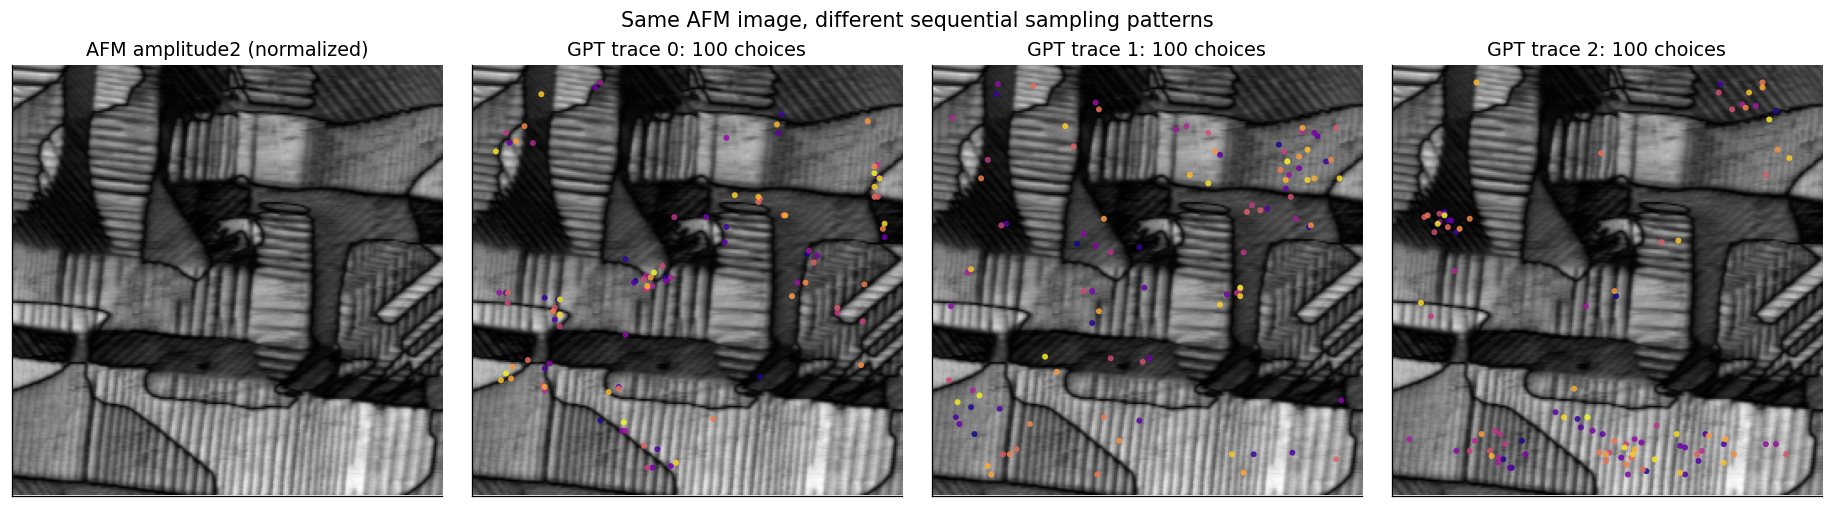

In [5]:
fig,axes=plt.subplots(1,4,figsize=(16,4.3),constrained_layout=True)
axes[0].imshow(scan,cmap='gray',vmin=0,vmax=1);axes[0].set_title('AFM amplitude2 (normalized)')
for j in range(3):
    key=f'gpt_decision_trace_{j}';xy=traces[key]['position']
    axes[j+1].imshow(scan,cmap='gray',vmin=0,vmax=1)
    axes[j+1].scatter(xy[:,0],xy[:,1],s=14,c=np.arange(1,101),cmap='plasma',alpha=.85,edgecolors='none')
    axes[j+1].set_title(f'GPT trace {j}: 100 choices')
for ax in axes:
    ax.set_xticks([]);ax.set_yticks([])
fig.suptitle('Same AFM image, different sequential sampling patterns',fontsize=13)
fig.savefig(FIG_DIR/'01_afm_and_gpt_paths.png',bbox_inches='tight');plt.show()

## 4. Infer candidate reward signals

For each patch we compute image intensity, dispersion, gradients, multiscale texture, entropy, bright-area, local contrast and related descriptors. For each decision we additionally compute **history-only** distances and sampling coverage. All features are computed without using the choice at the current step.

In [6]:
summary=run_analyses(traces,features,OUTPUT_ROOT)
ranked=summary['hypotheses'].groupby('trace',sort=False).head(1)
display(ranked.rename(columns={'train_accuracy':'exploratory_full_trace_top1'}))

,trace,feature,direction,exploratory_full_trace_top1
0,gpt_decision_trace_0,min_prev_distance,min,0.32
5,gpt_decision_trace_1,pixel_skew,min,0.22
10,gpt_decision_trace_2,blur_variance,min,0.37
15,simulated_decision_trace_0,mean,max,0.99
20,simulated_decision_trace_1,mean,min,0.99
25,simulated_decision_trace_2,std,min,0.83
30,simulated_decision_trace_3,blur_variance,max,0.27
35,simulated_decision_trace_4,past_coverage,max,0.41
40,simulated_decision_trace_5,min_prev_distance,min,0.43
45,simulated_decision_trace_6,past_coverage,max,0.36


### Synthetic-policy discovery — held-out 40 decisions

Each simulated trace has its own rule. Only the first 60 choices of each simulated trace train its model; decisions 61–100 are held out. The best single-feature hypothesis is chosen from training only. Training and scoring are **not pooled with GPT traces**.

Test top-1 accuracy (%),conditional-linear,extra-trees,one-feature
Synthetic policy,,,
simulated_decision_trace_0,82.5,72.5,100.0
simulated_decision_trace_1,95.0,87.5,100.0
simulated_decision_trace_2,85.0,82.5,75.0
simulated_decision_trace_3,27.5,40.0,22.5
simulated_decision_trace_4,60.0,72.5,32.5
simulated_decision_trace_5,65.0,75.0,32.5
simulated_decision_trace_6,35.0,60.0,32.5
simulated_decision_trace_7,67.5,77.5,57.5


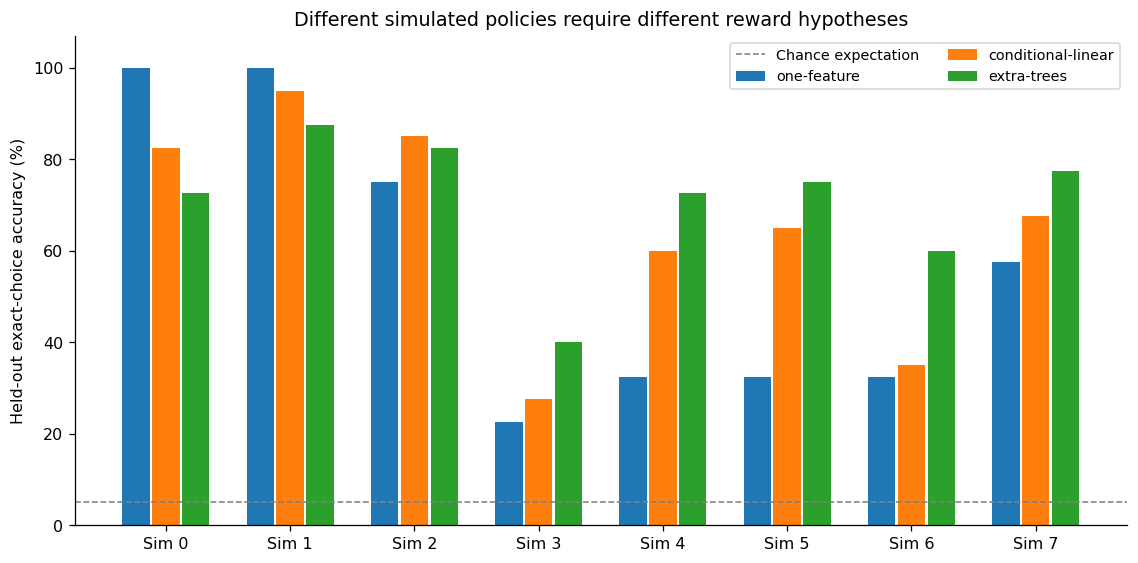

In [7]:
sim=summary['sim']
view=sim.pivot(index='trace',columns='method',values='top1')*100
display(view.round(1).rename_axis(index='Synthetic policy').rename_axis(columns='Test top-1 accuracy (%)'))
fig,ax=plt.subplots(figsize=(10,5))
methods=['one-feature','conditional-linear','extra-trees'];positions=np.arange(8)
for k,method in enumerate(methods):
    ax.bar(positions+(k-1)*.24,view[method].values,width=.22,label=method)
ax.axhline(5,color='gray',lw=1,ls='--',label='Chance expectation')
ax.set_xticks(positions,labels=[f'Sim {j}' for j in range(8)]);ax.set_ylim(0,107)
ax.set_ylabel('Held-out exact-choice accuracy (%)');ax.set_title('Different simulated policies require different reward hypotheses')
ax.legend(ncol=2,fontsize=9);fig.tight_layout()
fig.savefig(FIG_DIR/'02_synthetic_policy_comparison.png',bbox_inches='tight');plt.show()

## 5. Primary experiment: predict future GPT decisions

**Chronological model-selection protocol:** first 30 decisions train candidate reward models; the next 30 choose the family (single feature, conditional linear reward, extra trees, or average brightness); retrain the selected family on steps 1–60; report exact-choice accuracy on steps 61–100 only. Separate model selection per trace captures different objectives without contaminating test steps.

In [8]:
prospective,chosen=prospective_agent_model(traces,features,OUTPUT_ROOT)
adaptive,adaptive_explanations=run_adaptive_gpt(traces,features,OUTPUT_ROOT)
display(prospective[['trace','chosen_model','validation_top1','top1','top3','mrr','mean_rank']].round(3))
hits=int(round(prospective['top1'].sum()*40));total=3*40
rate=hits/total;test=binomtest(hits,total,p=1/20,alternative='greater')
ci=binomtest(hits,total).proportion_ci(confidence_level=.95,method='wilson')
print(f'Aggregate prospective exact-choice hits: {hits}/{total} = {rate:.1%}')
print(f'95% Wilson interval: [{ci.low:.1%}, {ci.high:.1%}] (naive independent-choice approximation)')
print(f'Exploratory binomial p versus 5%: {test.pvalue:.2e} (does not account for temporal dependence)')
print('Important: all experiments are from a single AFM image; new-scan generalization is not established.')

,trace,chosen_model,validation_top1,top1,top3,mrr,mean_rank
0,gpt_decision_trace_0,trees,0.300,0.275,0.60,0.474,4.40
1,gpt_decision_trace_1,trees,0.300,0.225,0.55,0.433,4.75
2,gpt_decision_trace_2,trees,0.533,0.350,0.75,0.585,2.85


Aggregate prospective exact-choice hits: 34/120 = 28.3%
95% Wilson interval: [21.0%, 37.0%] (naive independent-choice approximation)
Exploratory binomial p versus 5%: 7.58e-17 (does not account for temporal dependence)
Important: all experiments are from a single AFM image; new-scan generalization is not established.


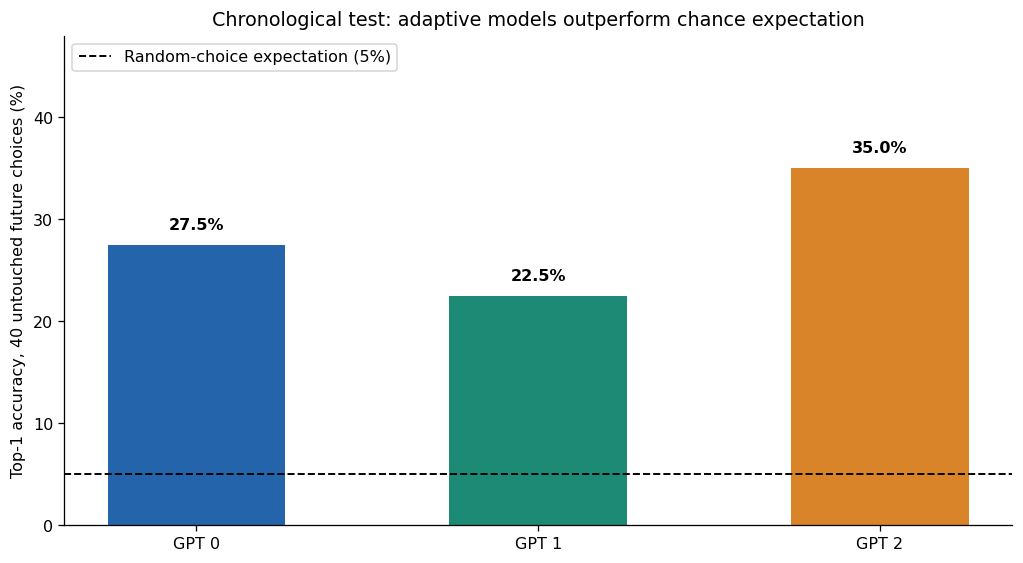

In [9]:
fig,ax=plt.subplots(figsize=(9,5))
vals=prospective['top1'].values*100
bars=ax.bar([f'GPT {i}' for i in range(3)],vals,color=[COLORS[f'gpt_decision_trace_{i}'] for i in range(3)],width=.52)
ax.axhline(5,color='black',ls='--',lw=1.2,label='Random-choice expectation (5%)')
for bar,v in zip(bars,vals):ax.text(bar.get_x()+bar.get_width()/2,v+1.5,f'{v:.1f}%',ha='center',weight='bold')
ax.set_ylim(0,max(vals)+13);ax.set_ylabel('Top-1 accuracy, 40 untouched future choices (%)')
ax.set_title('Chronological test: adaptive models outperform chance expectation')
ax.legend(loc='upper left');fig.tight_layout()
fig.savefig(FIG_DIR/'03_prospective_gpt_accuracy.png',bbox_inches='tight');plt.show()

### Model families compared on the same withheld decisions

For transparency, the models trained on decisions 1–60 are also evaluated on 61–100. This **secondary diagnostic** is not the primary score because it compares methods using test-suffix outcomes after the fact; use the prospective family-selection score above for the headline.

trace,gpt_decision_trace_0,gpt_decision_trace_1,gpt_decision_trace_2
method,,,
adaptive-extra-trees,27.5,22.5,35.0
adaptive-linear,12.5,20.0,30.0
best-training-feature,40.0,7.5,32.5
fixed-candidate-0,0.0,5.0,5.0
mean-high,0.0,12.5,30.0


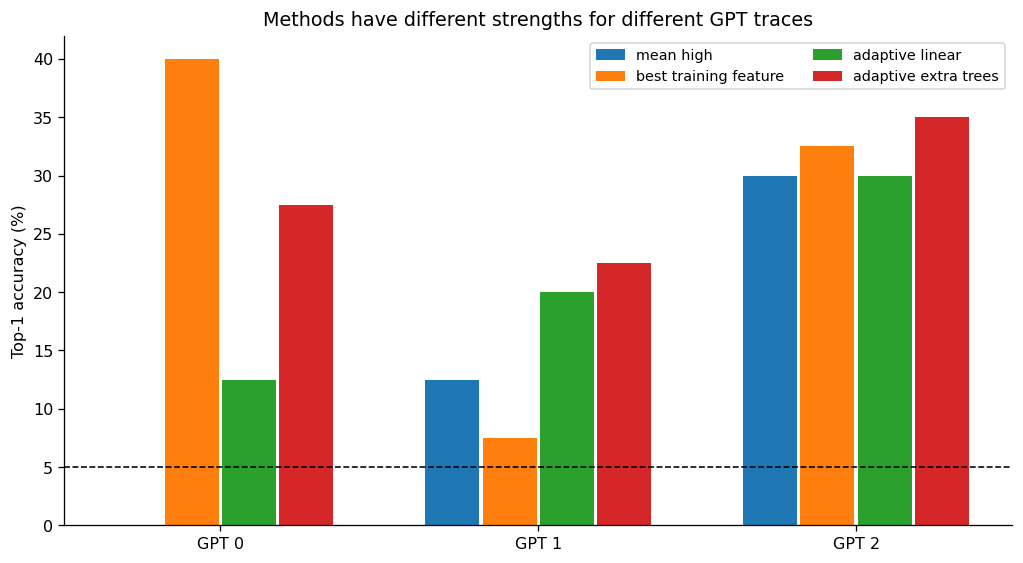

In [10]:
a=adaptive.pivot(index='method',columns='trace',values='top1')*100
display(a.round(1))
fig,ax=plt.subplots(figsize=(9,5));x=np.arange(3)
methods=['mean-high','best-training-feature','adaptive-linear','adaptive-extra-trees']
for j,k in enumerate(methods):
    vals=adaptive[adaptive.method==k].set_index('trace').loc[[f'gpt_decision_trace_{i}' for i in range(3)]]['top1'].values*100
    ax.bar(x+(j-1.5)*.18,vals,width=.17,label=k.replace('-',' '))
ax.axhline(5,ls='--',color='black',lw=1)
ax.set_xticks(x,[f'GPT {i}' for i in range(3)]);ax.set_ylabel('Top-1 accuracy (%)')
ax.set_title('Methods have different strengths for different GPT traces')
ax.legend(fontsize=9,ncol=2);fig.tight_layout()
fig.savefig(FIG_DIR/'04_adaptive_model_comparison.png',bbox_inches='tight');plt.show()

## 6. Cross-trace transfer as a more stringent generalization check

The held-out trace 2 uses new candidate sets; traces 0 and 1 share their exact candidate sets with one another and all synthetic traces. Thus the transfer result on GPT 2 is informative about a **new selection sequence and new candidate sets on the same AFM scan**, not a new AFM image.

heldout_trace,gpt_decision_trace_0,gpt_decision_trace_1,gpt_decision_trace_2
method,,,
conditional-linear,2.0,13.0,7.0
edge-energy-high,14.0,0.0,3.0
entropy-high,15.0,0.0,0.0
extra-trees,1.0,3.0,3.0
fixed-candidate-0,1.0,5.0,8.0
history-avoid,1.0,7.0,3.0
mean-high,0.0,8.0,20.0
mean-low,0.0,4.0,13.0
novelty-high,1.0,5.0,3.0


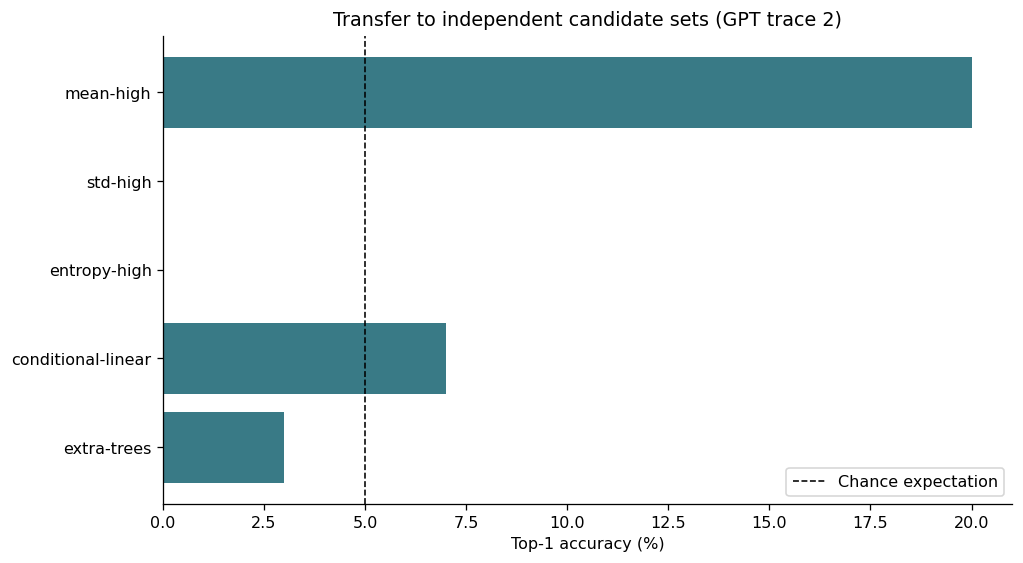

In [11]:
cross=summary['gpt']
piv=cross.pivot(index='method',columns='heldout_trace',values='top1')*100
display(piv.round(1))
fig,ax=plt.subplots(figsize=(9,5))
show=['mean-high','std-high','entropy-high','conditional-linear','extra-trees']
vals=piv.loc[show,'gpt_decision_trace_2']
ax.barh(show,vals,color='#397A86');ax.axvline(5,color='black',ls='--',lw=1,label='Chance expectation')
ax.set_xlabel('Top-1 accuracy (%)');ax.set_title('Transfer to independent candidate sets (GPT trace 2)')
ax.invert_yaxis();ax.legend();fig.tight_layout()
fig.savefig(FIG_DIR/'05_cross_trace_transfer.png',bbox_inches='tight');plt.show()

## 7. Explain a held-out decision visually

Blue denotes actual and predicted together, green denotes actual-only, red denotes predicted-only. A prospective extra-trees model for GPT 0 was selected on validation decisions and trained exclusively on steps 1–60.

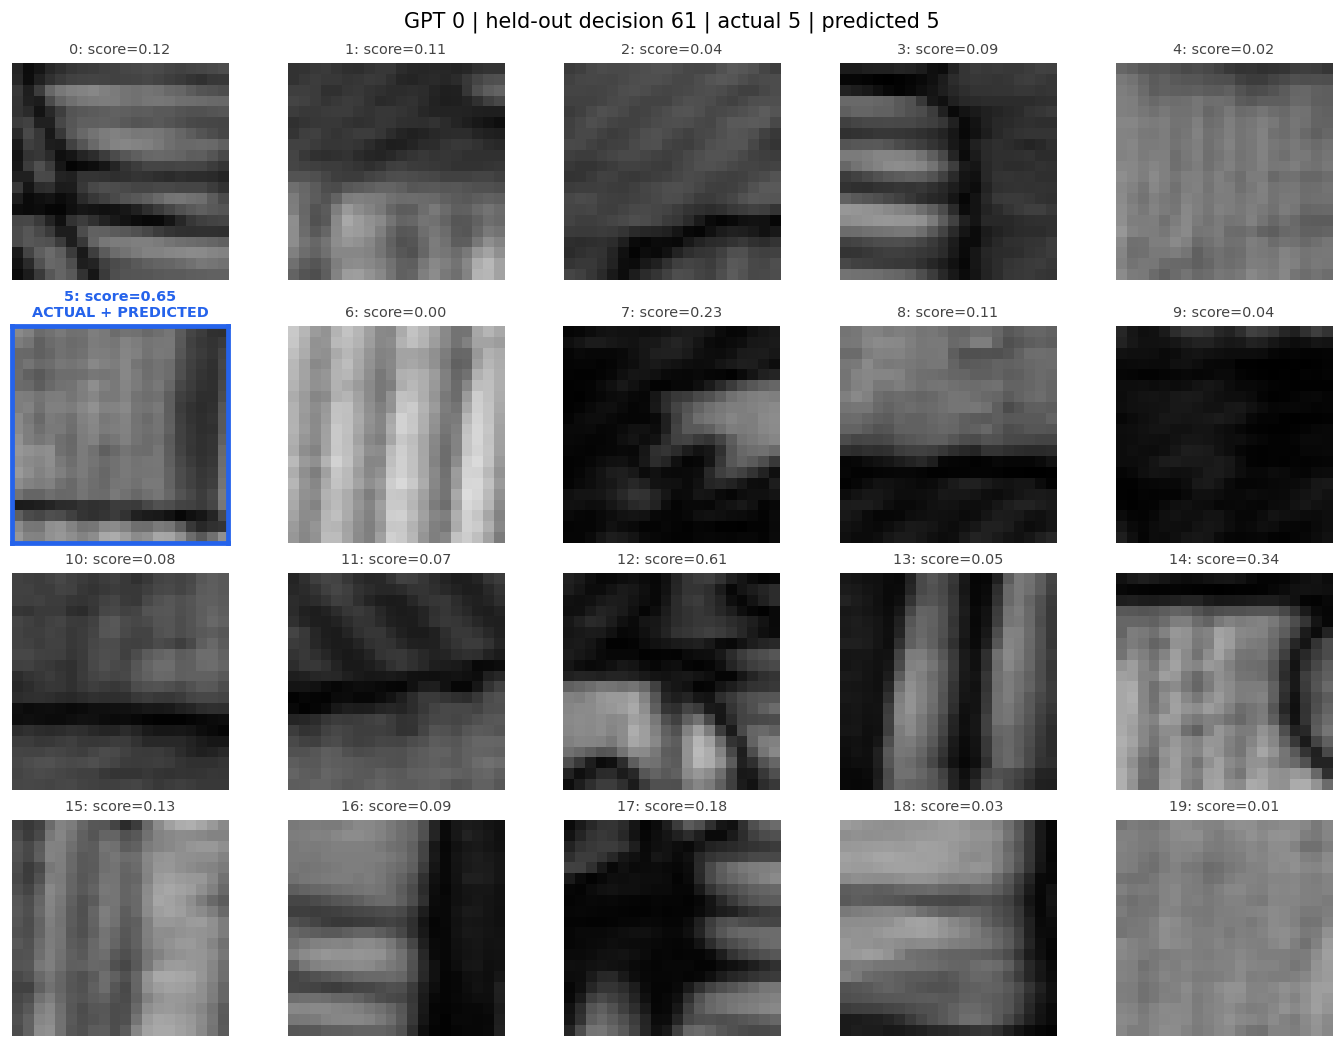

In [12]:
trace_name='gpt_decision_trace_0';decision_step=60  # 0-based: first test decision
train_features=features[trace_name].iloc[:1200];test_step=features[trace_name].iloc[decision_step*20:(decision_step+1)*20]
choice_y=traces[trace_name]['choice']
scores,interpretable_tree=extra_trees_scores(train_features,choice_y[:60],test_step)
scores=scores.ravel();actual=int(choice_y[decision_step]);pred=int(np.argmax(scores))
patches=traces[trace_name]['patches'][decision_step]
fig,axes=plt.subplots(4,5,figsize=(12,9),constrained_layout=True)
for j,ax in enumerate(axes.flat):
    ax.imshow(patches[j],cmap='gray',vmin=0,vmax=1)
    tag=('ACTUAL + PREDICTED' if j==actual==pred else 'ACTUAL' if j==actual else 'PREDICTED' if j==pred else '')
    color=('#2563EB' if j==actual==pred else '#168A63' if j==actual else '#BE3737' if j==pred else '#444444')
    ax.set_title(f'{j}: score={scores[j]:.2f}'+(f'\n{tag}' if tag else ''),fontsize=9,color=color,weight='bold' if tag else 'normal')
    for spine in ax.spines.values():spine.set_visible(bool(tag));spine.set_edgecolor(color);spine.set_linewidth(3)
    ax.set_xticks([]);ax.set_yticks([])
fig.suptitle(f'GPT 0 | held-out decision {decision_step+1} | actual {actual} | predicted {pred}',fontsize=13)
fig.savefig(FIG_DIR/'06_candidate_decision_explanation.png',bbox_inches='tight');plt.show()

### Which patch attributes are associated with model decisions?

These are predictive feature importances of the fitted classifier, **not GPT's internal attention weights, a recovered prompt, or causal explanations**.

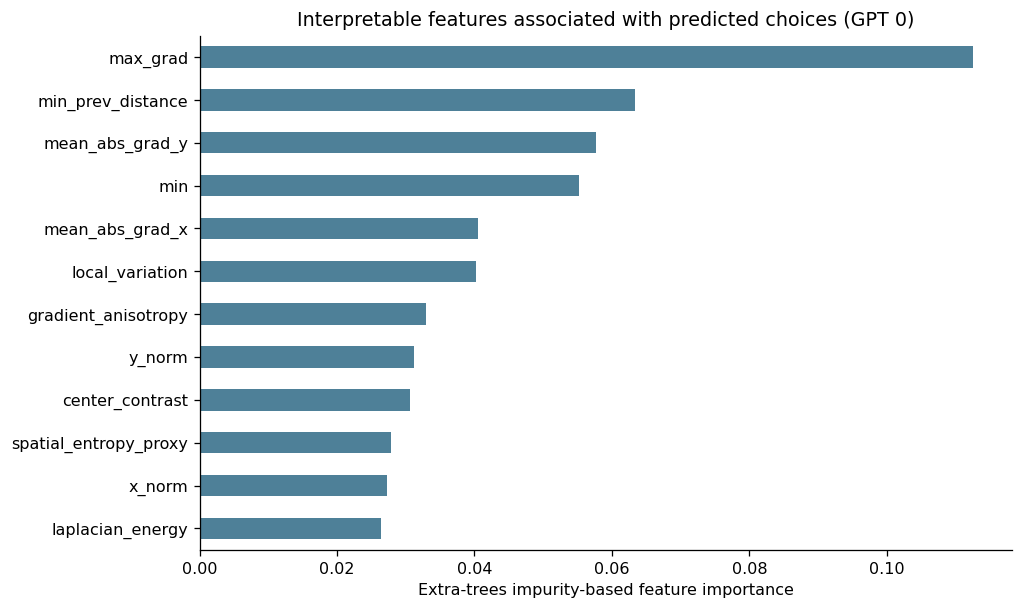

,relative_feature_importance
max_grad,0.113
min_prev_distance,0.063
mean_abs_grad_y,0.058
min,0.055
mean_abs_grad_x,0.040
local_variation,0.040
gradient_anisotropy,0.033
y_norm,0.031
center_contrast,0.031
spatial_entropy_proxy,0.028


In [13]:
imp=pd.Series(interpretable_tree.feature_importances_,index=train_features.columns).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(9,5.4))
imp.head(12).iloc[::-1].plot(kind='barh',ax=ax,color='#4E8098')
ax.set_xlabel('Extra-trees impurity-based feature importance')
ax.set_title('Interpretable features associated with predicted choices (GPT 0)')
fig.tight_layout();fig.savefig(FIG_DIR/'07_feature_importance.png',bbox_inches='tight');plt.show()
display(imp.head(12).rename('relative_feature_importance').to_frame().round(3))

## 8. Conclusions, uncertainty, and next experiments

The notebook prints the exact performance results above. The simulated policies show that simple reward functions can sometimes be recovered with perfect held-out accuracy (e.g., extreme mean intensity), whereas GPT choices vary by trace. A context-conditioned / online-adaptive model is therefore a better practical hypothesis than a single universal hand-designed rule.

**Limitations.** This was designed and tested retrospectively on the organizer data, so independent future evaluation is required. (1) Only three GPT traces with 100 decisions each, all on the same AFM scan; (2) teacher-forced previous choices are assumed known when predicting the next measurement; (3) temporal correlation and reused candidate patches reduce effective sample size; (4) full-trace exploratory feature rankings cannot be used as unbiased test scores; (5) importance scores are predictive association, not discovered hidden objectives.

**Next experiments.** Collect GPT traces with the exact sampling prompt, temperature/seed where available, and several independent AFM scans. Compare within-prompt, out-of-prompt and leave-one-scan-out holdouts. Test a contextual random utility model or pairwise-ranking model with calibrated abstention and prospective deployment, and measure model performance after adaptation with variable observation budgets.

In [14]:
print('COMPLETE: 11 traces loaded; AFM crop geometry validated; synthetic + GPT models evaluated.')
print(f'PRIMARY RESULT: {hits}/{total} = {rate:.1%} prospective accuracy vs 5% random expectation.')
print('All tables written to',OUTPUT_ROOT.resolve())
print('All visualizations written to',FIG_DIR.resolve())
print('Submission verdict: reproducible, with single-scan and small-sample limitations documented.')

COMPLETE: 11 traces loaded; AFM crop geometry validated; synthetic + GPT models evaluated.
PRIMARY RESULT: 34/120 = 28.3% prospective accuracy vs 5% random expectation.
All tables written to /mnt/data/AFM_Decision_Logic_Submission/results
All visualizations written to /mnt/data/AFM_Decision_Logic_Submission/figures
Submission verdict: reproducible, with single-scan and small-sample limitations documented.
